# Hourly Electricity Load

AEP hourly load is the megawatts used in one US region, hour by hour. Demand repeats through the day and through the week. I will keep the last two years, plot the daily average, the load by hour and a weekly decomposition, then train two models on a chronological 80/20 split. The first is linear regression on the last 24 hours. The second is a GRU. The deep model is the one I want here. I will compare RMSE in megawatts and save the GRU.


In [1]:
import kagglehub

path = kagglehub.dataset_download("robikscube/hourly-energy-consumption")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\robikscube\hourly-energy-consumption\versions\3


In [2]:
import os
import glob
import pandas as pd

csv_path = glob.glob(os.path.join(path, "**", "AEP_hourly.csv"), recursive=True)[0]
df = pd.read_csv(csv_path)
df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime").drop_duplicates("Datetime").set_index("Datetime")
df = df.tail(24 * 365 * 2)
df.head()


,AEP_MW
Datetime,
2016-08-02 23:00:00,17421.0
2016-08-03 00:00:00,15920.0
2016-08-03 01:00:00,14756.0
2016-08-03 02:00:00,13948.0
2016-08-03 03:00:00,13370.0


In [3]:
print(df.shape)
print(df.index.min(), df.index.max())
df["AEP_MW"].describe()


(17520, 1)
2016-08-02 23:00:00 2018-08-03 00:00:00


count    17520.000000
mean     14771.523059
std       2443.198204
min       9581.000000
25%      13023.000000
50%      14470.000000
75%      16250.250000
max      22759.000000
Name: AEP_MW, dtype: float64

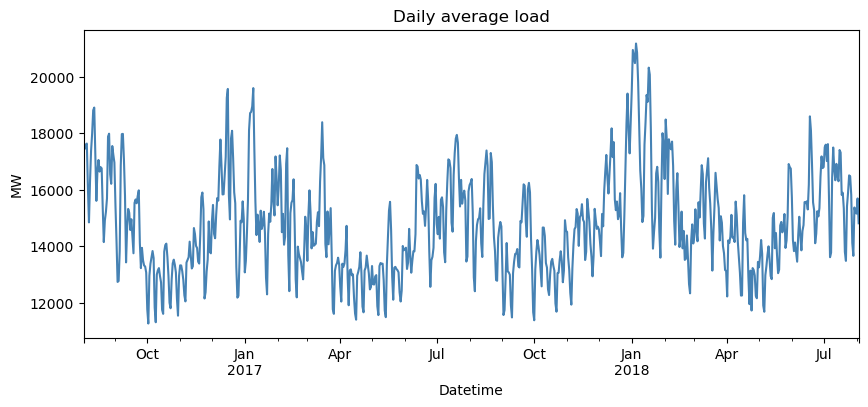

In [4]:
import matplotlib.pyplot as plt

daily = df["AEP_MW"].resample("D").mean()
daily.plot(figsize=(10, 4), color="steelblue")
plt.title("Daily average load")
plt.ylabel("MW")
plt.show()


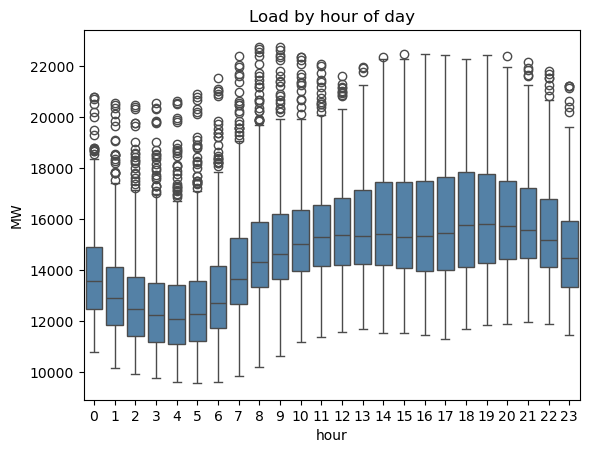

In [5]:
import seaborn as sns

sns.boxplot(x=df.index.hour, y=df["AEP_MW"], color="steelblue")
plt.title("Load by hour of day")
plt.xlabel("hour")
plt.ylabel("MW")
plt.show()


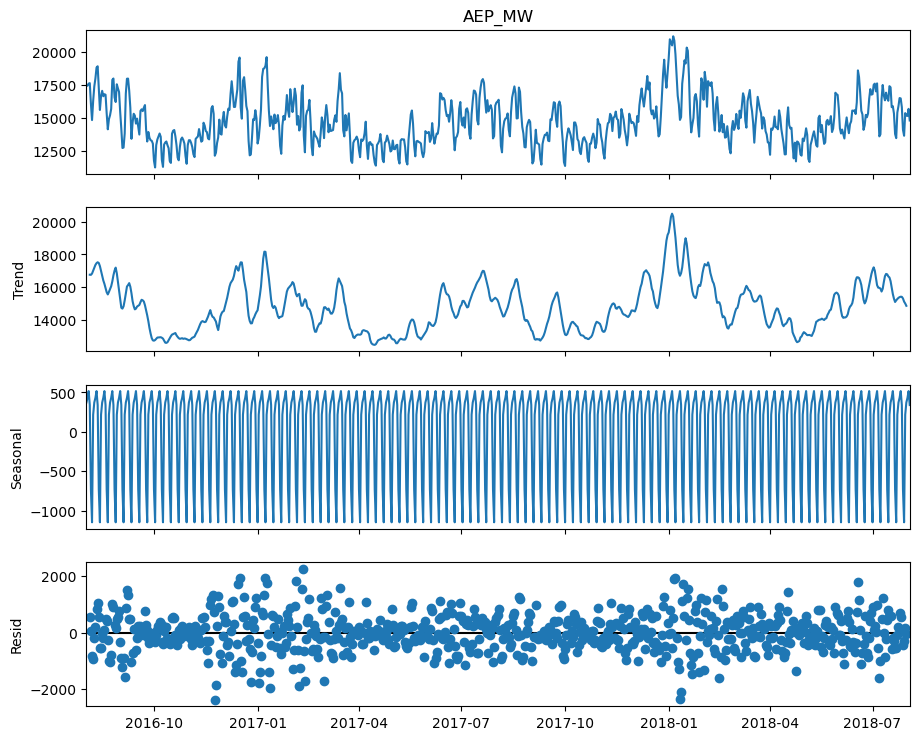

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(daily, model="additive", period=7)
fig = result.plot()
fig.set_size_inches(10, 8)
plt.show()


In [7]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import MinMaxScaler

window = 24
raw = df[["AEP_MW"]].to_numpy()
split_raw = int(len(raw) * 0.8)
scaler = MinMaxScaler()
scaler.fit(raw[:split_raw])
scaled = scaler.transform(raw).ravel()
x = sliding_window_view(scaled, window)[:-1][..., None]
y = scaled[window:]
n_train = split_raw - window
x_train, x_test = x[:n_train], x[n_train:]
y_train, y_test = y[:n_train], y[n_train:]
print(x_train.shape, x_test.shape)


(13992, 24, 1) (3504, 24, 1)


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lin = LinearRegression()
lin.fit(x_train.reshape(len(x_train), -1), y_train)
lin_pred = lin.predict(x_test.reshape(len(x_test), -1))
print("Linear RMSE", np.sqrt(mean_squared_error(
    scaler.inverse_transform(y_test.reshape(-1, 1)),
    scaler.inverse_transform(lin_pred.reshape(-1, 1)),
)))


Linear RMSE 193.9476948928977


In [9]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

dl = tf.keras.Sequential([
    layers.Input(shape=(window, 1)),
    layers.GRU(32),
    layers.Dropout(0.2),
    layers.Dense(1),
])
dl.compile(optimizer="adam", loss="mse")
hist = dl.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=256,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)
dl_pred = dl.predict(x_test, verbose=0).ravel()
print("GRU RMSE", np.sqrt(mean_squared_error(
    scaler.inverse_transform(y_test.reshape(-1, 1)),
    scaler.inverse_transform(dl_pred.reshape(-1, 1)),
)))


Epoch 1/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1062 - val_loss: 0.0159
Epoch 2/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0232 - val_loss: 0.0118
Epoch 3/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0148 - val_loss: 0.0068
Epoch 4/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0102 - val_loss: 0.0050
Epoch 5/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0077 - val_loss: 0.0042
Epoch 6/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0060 - val_loss: 0.0034
Epoch 7/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0050 - val_loss: 0.0028
Epoch 8/8
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0043 - val_loss: 0.0025
GRU RMSE 639.6387501668664


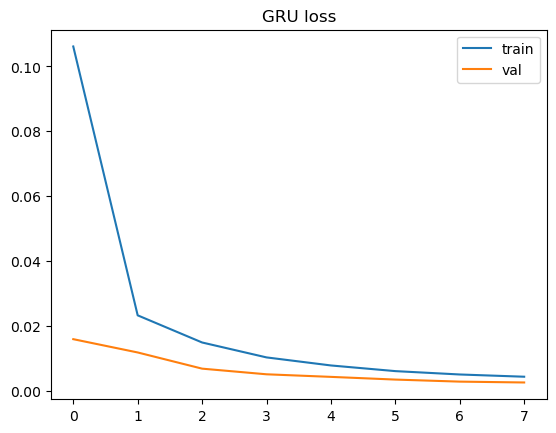

In [10]:
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("GRU loss")
plt.legend()
plt.show()


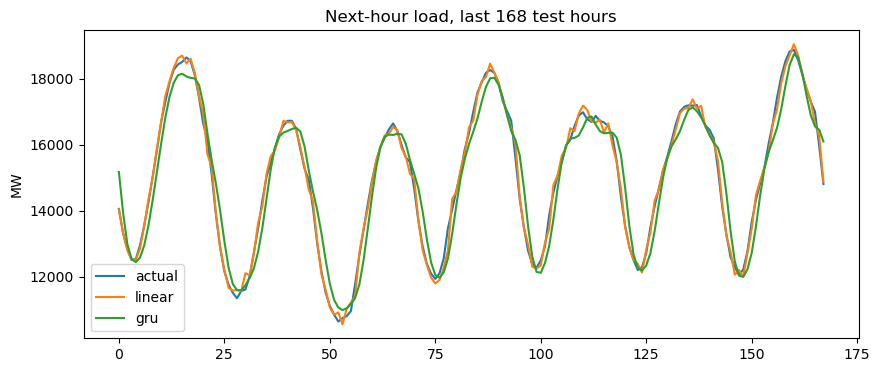

In [11]:
yt = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
yp_lin = scaler.inverse_transform(lin_pred.reshape(-1, 1)).ravel()
yp_dl = scaler.inverse_transform(dl_pred.reshape(-1, 1)).ravel()
plt.figure(figsize=(10, 4))
plt.plot(yt[-168:], label="actual")
plt.plot(yp_lin[-168:], label="linear")
plt.plot(yp_dl[-168:], label="gru")
plt.title("Next-hour load, last 168 test hours")
plt.ylabel("MW")
plt.legend()
plt.show()


In [12]:
dl.save("aep_load_gru.keras")


# Conclusion

I kept the last two years of AEP hourly load. The hour boxplot shows the daily cycle, and the decomposition of the daily average shows the weekly one. The split is chronological, so the test hours stay in the future. Linear regression on the last 24 hours is the autoregressive baseline. The GRU is the deep learning model: one day of hourly load goes in, and the next hour comes out. RMSE is in megawatts. The GRU is saved as aep_load_gru.keras.
